# Notebook 04 — Validación cruzada espacial vs aleatoria

Este notebook compara dos esquemas de validación cruzada para modelos con estructura espacial: una partición aleatoria de cuatro folds y una partición espacial por bloques 2 × 2.

La comparación busca mostrar cómo la validación cruzada aleatoria puede producir estimaciones demasiado optimistas cuando existen autocorrelación y dependencia espacial. En contraste, la validación espacial evalúa el desempeño en zonas no vistas y, por tanto, representa mejor el escenario de extrapolación espacial.

## Compatibilidad con Google Colab

La siguiente celda solo actúa cuando el notebook se ejecuta en Google Colab. En ese caso instala las dependencias necesarias, clona el repositorio y deja el directorio de trabajo en la raíz del proyecto.

En ejecución local, el notebook asume que se corre desde la raíz del repositorio o desde la carpeta `notebooks/`.

In [1]:
from pathlib import Path
import os
import subprocess
import sys

IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    print("Entorno Colab detectado. Clonando repositorio si es necesario...")

    repo_dir = Path("/content/repo")
    if not repo_dir.exists():
        subprocess.run(
            [
                "git",
                "clone",
                "-q",
                "https://github.com/linaq11/examen-2-gpboost.git",
                str(repo_dir),
            ],
            check=True,
        )

    os.chdir(repo_dir)
else:
    current_dir = Path.cwd()
    if current_dir.name == "notebooks":
        os.chdir(current_dir.parent)

print(f"Directorio de trabajo: {Path.cwd()}")

Directorio de trabajo: /sessions/optimistic-lucid-ptolemy/mnt/PERCEPCION REMOTA/Examen_2_GPBoost


In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RANDOM_SEED = 1
TEST_GRID_RMSE = 0.6073

DATA_DIR = Path("data")
FIGURE_DIR = Path("figuras")

FIGURE_DIR.mkdir(parents=True, exist_ok=True)

np.random.seed(RANDOM_SEED)

## 1. Datos y tabla de resultados

El notebook utiliza la tabla de resultados generada previamente para comparar los esquemas de validación. También carga el conjunto simulado para dejar explícito el vínculo con los datos base, aunque la figura se construye a partir de la tabla agregada.

In [3]:
required_files = {
    "training_data": DATA_DIR / "simulado_train_seed1.csv",
    "cv_results": DATA_DIR / "tabla_cv_espacial.csv",
}

missing_files = [str(path) for path in required_files.values() if not path.exists()]
if missing_files:
    raise FileNotFoundError(
        "No se encontraron los siguientes archivos requeridos:\n"
        + "\n".join(f"- {path}" for path in missing_files)
    )

training_data = pd.read_csv(required_files["training_data"])
cv_results = pd.read_csv(required_files["cv_results"])

feature_columns = ["X1", "X2"]
coord_columns = ["s_1", "s_2"]

X = training_data[feature_columns].to_numpy()
y = training_data["y"].to_numpy()
coords = training_data[coord_columns].to_numpy()

cv_results

,esquema,n_folds,RMSE_medio,RMSE_sd,gap_vs_test_pct
0,CV aleatoria k=4,4,0.5829,0.0357,-4.0117
1,CV espacial 2x2 bloques,4,0.7015,0.0598,15.5167


## 2. Visualización del contraste entre CV y test

El valor de referencia corresponde al RMSE obtenido sobre la grilla regular de evaluación. La validación cruzada aleatoria queda por debajo de ese valor, lo que indica una estimación optimista del error. La validación espacial queda por encima, lo que refleja una evaluación más exigente para predicción en zonas espacialmente independientes.

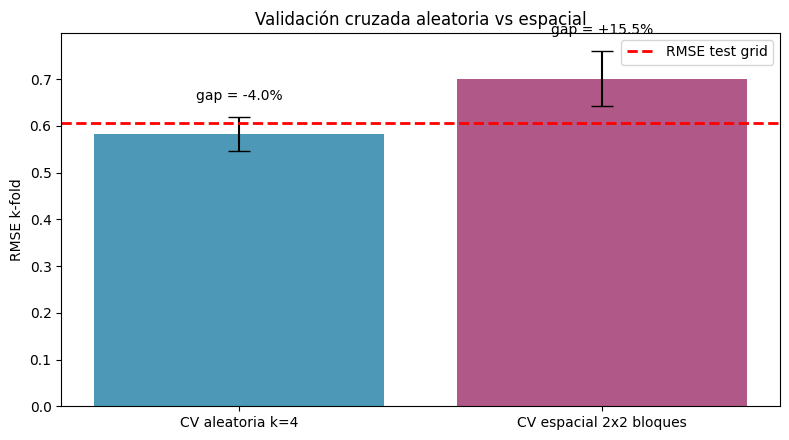

Figura guardada en: figuras/fig7_cv_espacial_vs_aleatoria.png


In [4]:
fig, ax = plt.subplots(figsize=(8, 4.5))

x_positions = np.arange(len(cv_results))

bars = ax.bar(
    x_positions,
    cv_results["RMSE_medio"],
    yerr=cv_results["RMSE_sd"],
    capsize=8,
    color=["#2E86AB", "#A23B72"],
    alpha=0.85,
)

ax.axhline(
    TEST_GRID_RMSE,
    color="red",
    linestyle="--",
    linewidth=2,
    label="RMSE test grid",
)

ax.set_xticks(x_positions)
ax.set_xticklabels(cv_results["esquema"])
ax.set_ylabel("RMSE k-fold")
ax.set_title("Validación cruzada aleatoria vs espacial")
ax.legend()

for index, row in cv_results.iterrows():
    label_y = row["RMSE_medio"] + row["RMSE_sd"] + 0.03
    ax.text(
        index,
        label_y,
        f"gap = {row['gap_vs_test_pct']:+.1f}%",
        ha="center",
        va="bottom",
    )

fig.tight_layout()

output_path = FIGURE_DIR / "fig7_cv_espacial_vs_aleatoria.png"
fig.savefig(output_path, dpi=150, bbox_inches="tight")
plt.show()

print(f"Figura guardada en: {output_path}")

## 3. Lectura metodológica

La validación cruzada aleatoria produce un RMSE cercano a 0,58, aproximadamente 4 % menor que el RMSE de referencia. Esto sugiere un desempeño mejor del que realmente se obtiene al evaluar sobre una grilla independiente.

La validación cruzada espacial produce un RMSE cercano a 0,70, aproximadamente 15,5 % mayor que el RMSE de referencia. Aunque esta estimación es más conservadora, resulta metodológicamente más adecuada cuando el objetivo es predecir en zonas no muestreadas.

Para un flujo de monitoreo ambiental con predicción espacial, la validación espacial es el criterio más defendible, porque evalúa explícitamente la capacidad del modelo para generalizar fuera de las vecindades usadas durante el entrenamiento.